<a href="https://colab.research.google.com/github/Njeri-Kiarie/Final_Capstone/blob/main/Salama_DistilBERT_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Verifying the selected GPU is available
import torch

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

PyTorch version: 2.11.0+cu130
GPU available: True
GPU name: Tesla T4


In [3]:
# Uploading the prepared datasets
from google.colab import files

uploaded = files.upload()

Saving dev_chunks (3).json to dev_chunks (3).json
Saving test_chunks (3).json to test_chunks (3).json
Saving train_chunks.json to train_chunks.json


In [4]:
# Verify the upload
import os

for filename in [
    "train_chunks.json",
    "dev_chunks_cleaned.json",
    "test_chunks_cleaned.json"
]:
    print(filename, ":", os.path.exists(filename))

train_chunks.json : True
dev_chunks_cleaned.json : False
test_chunks_cleaned.json : False


In [5]:
# Loading the JSON datasets
import pandas as pd

# Load the prepared datasets
train_chunks = pd.read_json("train_chunks.json")
dev_chunks = pd.read_json("dev_chunks (3).json")
test_chunks_df = pd.read_json("test_chunks (3).json")

# Check their shapes
print("Training:", train_chunks.shape)
print("Development:", dev_chunks.shape)
print("Testing:", test_chunks_df.shape)

# Check available columns
print("\nColumns:")
print(train_chunks.columns.tolist())

Training: (3252, 6)
Development: (328, 6)
Testing: (504, 6)

Columns:
['narrative_id', 'input_ids', 'gbv_related', 'gbv_type_labels', 'gbv_event_status', 'status_label']


A pytorch dataset allows us to retrieve individual text chunks and their corresponding labels during model training.

In [6]:
# Creating the custom pytorch dataset
import torch
from torch.utils.data import Dataset

class GBVDataset(Dataset):
    def __init__(self, dataframe):
        self.data = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        return {
            "input_ids": torch.tensor(
                row["input_ids"], dtype=torch.long
            ),
            "gbv_related": torch.tensor(
                row["gbv_related"], dtype=torch.float32
            ),
            "gbv_type_labels": torch.tensor(
                row["gbv_type_labels"], dtype=torch.float32
            ),
            "status_label": torch.tensor(
                row["status_label"], dtype=torch.long
            ),
            "narrative_id": row["narrative_id"]
        }

In [7]:
# Creating and verifying the pytorch dataset objects
# Create PyTorch datasets
train_dataset = GBVDataset(train_chunks)
dev_dataset = GBVDataset(dev_chunks)
test_dataset = GBVDataset(test_chunks_df)

# Check dataset sizes
print("Training samples:", len(train_dataset))
print("Development samples:", len(dev_dataset))
print("Testing samples:", len(test_dataset))

# Inspect one training sample
sample = train_dataset[0]

print("\nSample input shape:", sample["input_ids"].shape)
print("Binary GBV label:", sample["gbv_related"])
print("GBV type labels:", sample["gbv_type_labels"])
print("Temporal label:", sample["status_label"])
print("Narrative ID:", sample["narrative_id"])

Training samples: 3252
Development samples: 328
Testing samples: 504

Sample input shape: torch.Size([206])
Binary GBV label: tensor(1.)
GBV type labels: tensor([1., 0., 0., 0.])
Temporal label: tensor(1)
Narrative ID: Question 2


All training, development and testing chunks have successfully loaded. The sample contains 211 tokens, the narrative is gbv related, Domestic violence is the only GBV category identified and is ongoing.

Since our narratives have different token lengths, Pytorch cannot combine sequences of different lenghts into a single tensor. We therefore use dynamic padding which pads each batch only to the length of its longest sequence.

In [8]:
# Creating the collate_fn for dynamic padding
from torch.nn.utils.rnn import pad_sequence

def collate_fn(batch):

    # Pad token sequences to the longest sequence in the batch
    input_ids = pad_sequence(
        [item["input_ids"] for item in batch],
        batch_first=True,
        padding_value=0
    )

    # Attention mask: 1 for actual tokens, 0 for padding
    attention_mask = (input_ids != 0).long()

    # Combine classification labels
    gbv_related = torch.stack([
        item["gbv_related"] for item in batch
    ])

    gbv_type_labels = torch.stack([
        item["gbv_type_labels"] for item in batch
    ])

    status_labels = torch.stack([
        item["status_label"] for item in batch
    ])

    narrative_ids = [
        item["narrative_id"] for item in batch
    ]

    return {
        "input_ids": input_ids,
        "attention_mask": attention_mask,
        "gbv_related": gbv_related,
        "gbv_type_labels": gbv_type_labels,
        "status_label": status_labels,
        "narrative_id": narrative_ids
    }

We also use the attention mask to distinguish actual tokens from padding tokens. Hence the model will ignore padding positions when calculating attention.

Dataloaders then organise our data into batches and make it easier to train and evaluate DistilBert

In [9]:
# Creating the dataloaders
from torch.utils.data import DataLoader

batch_size = 8

# Training DataLoader
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    collate_fn=collate_fn
)

# Development DataLoader
dev_loader = DataLoader(
    dev_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

# Test DataLoader
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    collate_fn=collate_fn
)

# Check number of batches
print("Training batches:", len(train_loader))
print("Development batches:", len(dev_loader))
print("Testing batches:", len(test_loader))

Training batches: 407
Development batches: 41
Testing batches: 63


We use `shuffle=True` during training since it changes the order in which the model encounters examples helping to reduce order bias.

We use `shuffle=False` for development and testing to keep predictions in a consistent order which makes it easier to aggregate chunk predictions using their `narrative_id`

Before training DistilBert, we verify that the DataLoader correctly combines the tokenized text, attention masks and classification labels

In [10]:
# Inspecting one training batch
# Retrieve one batch from the training DataLoader
batch = next(iter(train_loader))

print("Input IDs shape:", batch["input_ids"].shape)
print("Attention mask shape:", batch["attention_mask"].shape)

print("\nBinary GBV labels shape:", batch["gbv_related"].shape)
print("GBV type labels shape:", batch["gbv_type_labels"].shape)
print("Temporal labels shape:", batch["status_label"].shape)

print("\nNarrative IDs:", batch["narrative_id"])

# Confirm no sequence exceeds DistilBERT's maximum length
print("\nMaximum sequence length:", batch["input_ids"].shape[1])

Input IDs shape: torch.Size([8, 488])
Attention mask shape: torch.Size([8, 488])

Binary GBV labels shape: torch.Size([8])
GBV type labels shape: torch.Size([8, 4])
Temporal labels shape: torch.Size([8])

Narrative IDs: ['Question 4152', 'Question 2064', 'Question 3260', 'Question 3923', 'Question 3625', 'Question 58', 'Question 1813', 'Question 768']

Maximum sequence length: 488


We'll begin with our first task; predicting whether a narrative is GBV-related or not i.e: (1) or (0)

In [11]:
# Loading DistilBert for GBV binary classification
from transformers import AutoModelForSequenceClassification
import torch

# Select GPU
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Load pretrained DistilBERT
binary_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=1
)

# Move model to GPU
binary_model = binary_model.to(device)

print("Device:", device)
print("Model loaded successfully!")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Device: cuda
Model loaded successfully!


In [12]:
# Configuring the binary classifier's loss function and optimizer
import torch.nn as nn
from torch.optim import AdamW

# Calculate binary positive class weight from training narratives
positive_count = train_chunks.drop_duplicates("narrative_id")["gbv_related"].sum()
negative_count = train_chunks["narrative_id"].nunique() - positive_count

binary_pos_weight = torch.tensor(
    [negative_count / positive_count],
    dtype=torch.float32,
    device=device
)

# Binary classification loss
binary_loss_fn = nn.BCEWithLogitsLoss(
    pos_weight=binary_pos_weight
)

# Optimizer
binary_optimizer = AdamW(
    binary_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

print("Binary positive weight:", binary_pos_weight.item())
print("Learning rate:", binary_optimizer.param_groups[0]["lr"])
print("Loss function:", binary_loss_fn)

Binary positive weight: 1.4017502069473267
Learning rate: 2e-05
Loss function: BCEWithLogitsLoss()


The positive class weight means that misclassifying a GBV-positive example contributes approximately 1.4 times as much positive-class loss as it would without weighting.

In [13]:
# Configuring the training settings
from transformers import get_linear_schedule_with_warmup

# Training configuration
num_epochs = 3

# Total optimizer update steps
total_training_steps = len(train_loader) * num_epochs

# Learning-rate scheduler
binary_scheduler = get_linear_schedule_with_warmup(
    binary_optimizer,
    num_warmup_steps=int(0.1 * total_training_steps),
    num_training_steps=total_training_steps
)

print("Number of epochs:", num_epochs)
print("Training batches per epoch:", len(train_loader))
print("Total training steps:", total_training_steps)
print("Warmup steps:", int(0.1 * total_training_steps))

Number of epochs: 3
Training batches per epoch: 407
Total training steps: 1221
Warmup steps: 122


In [14]:
# Creating the binary classifier training function
from tqdm.auto import tqdm

def train_binary_epoch(model, dataloader, optimizer, scheduler, loss_fn, device):

    model.train()
    total_loss = 0

    progress_bar = tqdm(dataloader, desc="Training")

    for batch in progress_bar:

        # Move inputs and labels to GPU
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["gbv_related"].to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # One prediction per chunk
        logits = outputs.logits.squeeze(-1)

        # Calculate binary classification loss
        loss = loss_fn(logits, labels)

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Update model parameters
        optimizer.step()
        scheduler.step()

        # Track training loss
        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / len(dataloader)

The function:
1. Sets DistilBERT to training mode using model.train()
2. Process each batch of 8 text chunks on the GPU.
3. Generate one GBV Classification logit per chunk.
4. Calculate the weighted binary cross-entropy loss.
5. Update the model parameters through backpropagation.

Evaluating how well Salama identifies GBV-related narratives during training.

In [15]:
# Creating the binary classification validation function
import numpy as np
import pandas as pd
import torch

def validate_binary(model, dataloader, loss_fn, device):

    model.eval()
    total_loss = 0
    all_predictions = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["gbv_related"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            logits = outputs.logits.squeeze(-1)
            loss = loss_fn(logits, labels)

            total_loss += loss.item()

            # Convert logits into probabilities
            probabilities = torch.sigmoid(logits).cpu().numpy()

            for narrative_id, probability, label in zip(
                batch["narrative_id"],
                probabilities,
                labels.cpu().numpy()
            ):
                all_predictions.append({
                    "narrative_id": narrative_id,
                    "probability": float(probability),
                    "actual": int(label)
                })

    # Aggregate chunk predictions into narrative predictions
    predictions_df = pd.DataFrame(all_predictions)

    narrative_predictions = predictions_df.groupby(
        "narrative_id", as_index=False
    ).agg(
        probability=("probability", "mean"),
        actual=("actual", "first")
    )

    # Apply classification threshold
    narrative_predictions["predicted"] = (
        narrative_predictions["probability"] >= 0.5
    ).astype(int)

    y_true = narrative_predictions["actual"].to_numpy()
    y_pred = narrative_predictions["predicted"].to_numpy()

    # Calculate evaluation metrics
    accuracy = np.mean(y_true == y_pred)

    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))

    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    return {
        "loss": total_loss / len(dataloader),
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

Training the first training experiment for 3 epochs while evaluating the model on the development dataset after each epoch.

In [16]:
# Training and Validating DistilBERT
# Store training history
binary_history = []

best_f1 = -1.0

for epoch in range(num_epochs):

    print(f"\nEpoch {epoch + 1}/{num_epochs}")
    print("-" * 40)

    # Train for one epoch
    train_loss = train_binary_epoch(
        binary_model,
        train_loader,
        binary_optimizer,
        binary_scheduler,
        binary_loss_fn,
        device
    )

    # Evaluate on development data
    val_metrics = validate_binary(
        binary_model,
        dev_loader,
        binary_loss_fn,
        device
    )

    # Save results
    binary_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_metrics["loss"],
        "accuracy": val_metrics["accuracy"],
        "precision": val_metrics["precision"],
        "recall": val_metrics["recall"],
        "f1": val_metrics["f1"]
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_metrics['loss']:.4f}")
    print(f"Accuracy: {val_metrics['accuracy']:.4f}")
    print(f"Precision: {val_metrics['precision']:.4f}")
    print(f"Recall: {val_metrics['recall']:.4f}")
    print(f"F1 Score: {val_metrics['f1']:.4f}")

    # Save the best model based on validation F1
    if val_metrics["f1"] > best_f1:
        best_f1 = val_metrics["f1"]

        binary_model.save_pretrained(
            "salama_binary_best"
        )

        print("Best model saved!")

# Display training history
binary_results = pd.DataFrame(binary_history)

display(binary_results)


Epoch 1/3
----------------------------------------


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Training Loss: 0.3345
Validation Loss: 0.2908
Accuracy: 0.9685
Precision: 0.9587
Recall: 0.9667
F1 Score: 0.9627


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!

Epoch 2/3
----------------------------------------


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!

Epoch 3/3
----------------------------------------


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Training Loss: 0.0468
Validation Loss: 0.3191
Accuracy: 0.9720
Precision: 0.9590
Recall: 0.9750
F1 Score: 0.9669


,epoch,train_loss,val_loss,accuracy,precision,recall,f1
0,1,0.334548,0.290846,0.968531,0.958678,0.966667,0.962656
1,2,0.091632,0.299300,0.972028,0.959016,0.975000,0.966942
2,3,0.046803,0.319099,0.972028,0.959016,0.975000,0.966942


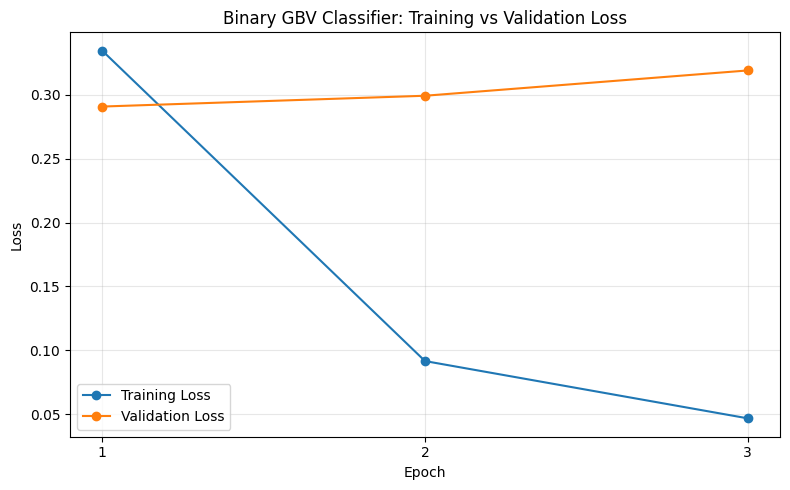

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    binary_results["epoch"],
    binary_results["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    binary_results["epoch"],
    binary_results["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("Binary GBV Classifier: Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(binary_results["epoch"])
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

Training loss decreased consistently across the three epochs, indicating that the DistilBERT model was learning patterns from the training data.

However, validation loss increased slightly from 0.2908 in Epoch 1 to 0.319 in Epoch 3, suggesting possible overfitting as training progressed.

Model performance improved between Epochs 1 and 2, with accuracy increasing from 96.85% to 97.20% and F1-score increasing from 96.27% to 96.69%.

Epochs 2 and 3 achieved identical classification metrics, indicating that additional training did not improve predictive performance.

Epoch 2 was selected as the best-performing checkpoint, achieving:

- Accuracy: 97.20%

- Precision: 95.90%

- Recall: 97.50%

- F1-score: 96.69%

In [18]:
# Examining the confusion matrix
from transformers import AutoModelForSequenceClassification

# Reload the best model (Epoch 3)
best_binary_model = AutoModelForSequenceClassification.from_pretrained(
    "salama_binary_best"
).to(device)

best_binary_model.eval()

# Get validation predictions
all_predictions = []

with torch.no_grad():
    for batch in dev_loader:
        outputs = best_binary_model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device)
        )

        probabilities = torch.sigmoid(
            outputs.logits.squeeze(-1)
        ).cpu().numpy()

        for narrative_id, probability, actual in zip(
            batch["narrative_id"],
            probabilities,
            batch["gbv_related"].numpy()
        ):
            all_predictions.append({
                "narrative_id": narrative_id,
                "probability": float(probability),
                "actual": int(actual)
            })

# Aggregate predictions at narrative level
validation_predictions = (
    pd.DataFrame(all_predictions)
    .groupby("narrative_id", as_index=False)
    .agg(
        probability=("probability", "mean"),
        actual=("actual", "first")
    )
)

validation_predictions["predicted"] = (
    validation_predictions["probability"] >= 0.5
).astype(int)

# Calculate confusion matrix counts
tn = ((validation_predictions["actual"] == 0) &
      (validation_predictions["predicted"] == 0)).sum()

fp = ((validation_predictions["actual"] == 0) &
      (validation_predictions["predicted"] == 1)).sum()

fn = ((validation_predictions["actual"] == 1) &
      (validation_predictions["predicted"] == 0)).sum()

tp = ((validation_predictions["actual"] == 1) &
      (validation_predictions["predicted"] == 1)).sum()

print("Confusion Matrix:")
print([[tn, fp], [fn, tp]])

print("\nTrue Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Confusion Matrix:
[[np.int64(161), np.int64(5)], [np.int64(3), np.int64(117)]]

True Negatives: 161
False Positives: 5
False Negatives: 3
True Positives: 117


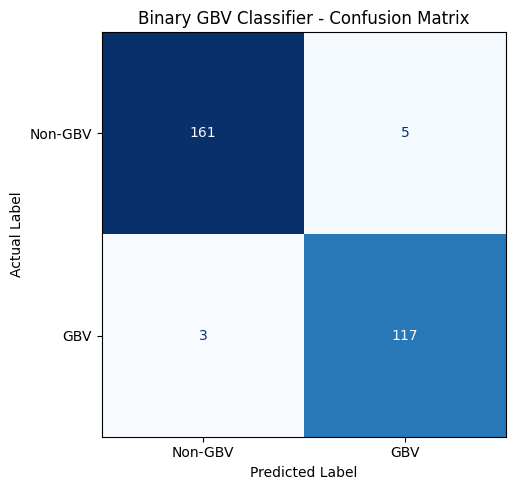

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np

# Create confusion matrix
cm = np.array([[tn, fp],
               [fn, tp]])

# Visualize confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non-GBV", "GBV"]
)

fig, ax = plt.subplots(figsize=(7, 5))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax,
    colorbar=False
)

plt.title("Binary GBV Classifier - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

In [20]:
# Examining the misclassified narratives
# Extract incorrectly classified narratives
misclassified = validation_predictions[
    validation_predictions["actual"] !=
    validation_predictions["predicted"]
].copy()

# Identify the error type
misclassified["error_type"] = misclassified.apply(
    lambda row: "False Negative"
    if row["actual"] == 1
    else "False Positive",
    axis=1
)

display(
    misclassified[
        ["narrative_id", "actual", "predicted",
         "probability", "error_type"]
    ].sort_values("error_type")
)

,narrative_id,actual,predicted,probability,error_type
110,Question 233,1,0,0.002712,False Negative
136,Question 283,1,0,0.120739,False Negative
140,Question 288,1,0,0.003966,False Negative
11,Question 109,0,1,0.997882,False Positive
15,Question 112,0,1,0.998000,False Positive
23,Question 120,0,1,0.997613,False Positive
103,Question 226,0,1,0.998374,False Positive
245,Question 420,0,1,0.990380,False Positive


In [37]:
# Investigating the original narratives
from transformers import AutoTokenizer

tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

# Examine the false negative
false_negative_ids = ["Question 233", "Question 283", "Question 288"]

for narrative_id in false_negative_ids:

    chunks = dev_chunks[
        dev_chunks["narrative_id"] == narrative_id
    ]

    print(f"\n{'=' * 60}")
    print("Narrative:", narrative_id)
    print("Number of chunks:", len(chunks))
    print("GBV type labels:", chunks.iloc[0]["gbv_type_labels"])
    print("Temporal status:", chunks.iloc[0]["gbv_event_status"])

    for i, token_ids in enumerate(chunks["input_ids"], start=1):
        text = tokenizer.decode(
            token_ids,
            skip_special_tokens=True
        )

        print(f"\nChunk {i}:")
        print(text)


Narrative: Question 233
Number of chunks: 1
GBV type labels: [0, 1, 0, 0]
Temporal status: past

Chunk 1:
breaking a 5 month streak of no self harm and 2 month streak of no suicidal thoughts. hi its 1 : 18am currently and i really really want to kill myself. i feel like the biggest failure of a human to ever exist. among other things, i was recently diagnosed with adhd and i feel like that was the nail in the coffin. i know this is bleak and unhealthy but i feel like a reject from the human manufacturing factory, like i was built to become a failure and there ’ s nothing i can do to change it. ive tried so so hard to but at the end of the day im still a piece of shit inconsiderate failure of a child / partner / friend. i thought i was getting better i really did. this year has been the worst year ever but despite my grandma dying, getting sexually assaulted by a close friend, getting diagnosed with adhd, and getting fired from my job im still here. i was on track to get better. i was 

The binary GBV classifier produced three false negatives during evaluation on the cleaned development dataset.

**Question 283 (sexual assualt):** The narrative had a brief sexual assault disclosure using sensored abbreviations 'sa' when talking about an abortion they performed in the past.

**Question 233 (Sexual Assault):** The narrative contained a brief sexual assault disclosure within a broader discussion of suicidal thoughts, self-harm and mental health challenges. The model may have placed greater emphasis on the dominant mental health-related content.

**Question 288 (Sexual Assault):** The narrative described past rape using censored terminology such as "r @ pe" and "r * ped". The model may have struggled to recognize these obfuscated expressions.

These errors suggest that the classifier may have difficulty identifying GBV disclosures in lengthy narratives, narratives involving multiple crises, and text containing censored terminology. Further analysis of prediction probabilities is required to confirm the underlying causes.

In [22]:
# Examining the false positives
false_positive_ids = misclassified.loc[
    misclassified["error_type"] == "False Positive",
    "narrative_id"
].tolist()

for narrative_id in false_positive_ids:

    chunks = dev_chunks[
        dev_chunks["narrative_id"] == narrative_id
    ]

    print(f"\n{'=' * 60}")
    print("Narrative:", narrative_id)
    print("GBV type labels:", chunks.iloc[0]["gbv_type_labels"])
    print("Temporal status:", chunks.iloc[0]["gbv_event_status"])

    for i, token_ids in enumerate(chunks["input_ids"], start=1):
        print(f"\nChunk {i}:")
        print(tokenizer.decode(token_ids, skip_special_tokens=True))


Narrative: Question 109
GBV type labels: [0, 0, 0, 0]
Temporal status: not_applicable

Chunk 1:
who else feels like they ' re only still living to spare the feelings of their family members? there ' s nothing in my life worth living for anymore. everything and everyone who brought any join into my life is gone. i ' m disabled, in poor health, i suffer abuse on a daily basis and i feel totally alone in this world. it would be a relief to be able to just stop existing. the only thing preventing me is the fact that i have 1 or 2 family members who i feel would be deeply affected if i were to check out on them. so i suffer through each day more alone then the last in order to spare their feelings. anyone else in a similar situation?

Narrative: Question 112
GBV type labels: [0, 0, 0, 0]
Temporal status: not_applicable

Chunk 1:
hopefully my finale lmao. i made a plan, just choosing a date, early next year i ' m thinking, i ' m gonna give away stuff then call someone to grab my body and de

The binary GBV classifier produced nine false positives during evaluation on the development dataset.

Manual examination revealed three patterns. First, some narratives described experiences of physical abuse, sexual assault or family violence despite being labelled as non-GBV, suggesting possible annotation inconsistencies. Second, some narratives contained ambiguous references to abuse without sufficient context to confirm GBV. Third, several narratives focused on other forms of distress, including financial difficulties, self-harm and online bullying, without clear GBV disclosures.

These findings suggest that some false positives may result from incomplete or ambiguous annotations, while others may reflect the model's difficulty distinguishing GBV-related content from other crisis narratives.

**Multilabel GBV Classification**

DistilBERT model will identify which types of GBV are present in a narrative.

Unlike binary classification, a narrative can belong to more than one category.

We'll use four output neurons with sigmoid activation, allowing each category to receive an independent probability.

In [23]:
# Initializing the multilabel distilBERT model
from transformers import AutoModelForSequenceClassification

# Four GBV categories
gbv_categories = [
    "domesticviolence",
    "rape",
    "sexualharassment",
    "childabuse_endangerment"
]

# Initialize DistilBERT for multi-label classification
multilabel_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=4,
    problem_type="multi_label_classification"
).to(device)

print("Number of GBV categories:", multilabel_model.config.num_labels)
print("Model device:", next(multilabel_model.parameters()).device)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Number of GBV categories: 4
Model device: cuda:0


In [24]:
# Checking for class imbalance
import numpy as np
import pandas as pd

# Get one label vector per narrative
train_labels = (
    train_chunks
    .drop_duplicates(subset="narrative_id")
    ["gbv_type_labels"]
)

# Convert label vectors into a DataFrame
label_df = pd.DataFrame(
    train_labels.tolist(),
    columns=gbv_categories
)

# Count positive and negative examples
class_distribution = pd.DataFrame({
    "Positive": label_df.sum(),
    "Negative": len(label_df) - label_df.sum()
})

class_distribution["Positive (%)"] = (
    class_distribution["Positive"] / len(label_df) * 100
).round(2)

display(class_distribution)

,Positive,Negative,Positive (%)
domesticviolence,500,2519,16.56
rape,407,2612,13.48
sexualharassment,373,2646,12.36
childabuse_endangerment,182,2837,6.03


In [25]:
import torch
import torch.nn as nn

# Calculate positive weights for each GBV category
positive_weights = (
    class_distribution["Negative"] /
    class_distribution["Positive"]
)

# Convert weights to a tensor on the GPU
multilabel_pos_weight = torch.tensor(
    positive_weights.values,
    dtype=torch.float32,
    device=device
)

# Define the weighted loss function
multilabel_loss_fn = nn.BCEWithLogitsLoss(
    pos_weight=multilabel_pos_weight
)

print("Positive class weights:")
for category, weight in zip(gbv_categories, multilabel_pos_weight):
    print(f"{category}: {weight.item():.4f}")

Positive class weights:
domesticviolence: 5.0380
rape: 6.4177
sexualharassment: 7.0938
childabuse_endangerment: 15.5879


In [26]:
# Setting up the optimizer and scheduler
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# Number of training epochs
multilabel_epochs = 3

# Initialize optimizer
multilabel_optimizer = AdamW(
    multilabel_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

# Calculate training steps
total_steps = len(train_loader) * multilabel_epochs

# Use 10% of training steps for warmup
warmup_steps = int(0.1 * total_steps)

# Initialize learning rate scheduler
multilabel_scheduler = get_linear_schedule_with_warmup(
    multilabel_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print("Training batches:", len(train_loader))
print("Epochs:", multilabel_epochs)
print("Total training steps:", total_steps)
print("Warmup steps:", warmup_steps)

Training batches: 407
Epochs: 3
Total training steps: 1221
Warmup steps: 122


In [27]:
# Creating the multilabel training function
from tqdm.auto import tqdm
import torch

def train_multilabel_epoch(model, dataloader, optimizer, scheduler, loss_fn):

    model.train()
    total_loss = 0

    progress_bar = tqdm(dataloader, desc="Training")

    for batch in progress_bar:

        # Move inputs and labels to GPU
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["gbv_type_labels"].to(device).float()

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Calculate weighted multi-label loss
        loss = loss_fn(outputs.logits, labels)

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        # Update model weights
        optimizer.step()

        # Update learning rate
        scheduler.step()

        # Track training loss
        total_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return total_loss / len(dataloader)

In [28]:
# Creating the multilabel validation function
from sklearn.metrics import (
    precision_recall_fscore_support,
    f1_score
)

import pandas as pd
import numpy as np
import torch

def validate_multilabel(model, dataloader, loss_fn):

    model.eval()

    total_loss = 0
    predictions = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["gbv_type_labels"].to(device).float()

            # Forward pass
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # Calculate validation loss
            loss = loss_fn(outputs.logits, labels)
            total_loss += loss.item()

            # Convert logits to probabilities
            probabilities = torch.sigmoid(
                outputs.logits
            ).cpu().numpy()

            # Store each chunk's predictions
            for narrative_id, probs, true_labels in zip(
                batch["narrative_id"],
                probabilities,
                labels.cpu().numpy()
            ):
                predictions.append({
                    "narrative_id": narrative_id,
                    "probabilities": probs,
                    "true_labels": true_labels
                })

    # Combine chunk predictions by narrative
    predictions_df = pd.DataFrame(predictions)

    narrative_results = (
        predictions_df.groupby("narrative_id")
        .agg({
            "probabilities": lambda x: np.mean(
                np.stack(x), axis=0
            ),
            "true_labels": "first"
        })
        .reset_index()
    )

    # Actual labels
    y_true = np.stack(
        narrative_results["true_labels"].values
    ).astype(int)

    # Predicted probabilities
    y_prob = np.stack(
        narrative_results["probabilities"].values
    )

    # Apply 0.5 threshold independently to each category
    y_pred = (y_prob >= 0.5).astype(int)

    # Calculate category-level metrics
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average=None,
            zero_division=0
        )
    )

    # Create category performance table
    category_metrics = pd.DataFrame({
        "Category": gbv_categories,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Support": support
    })

    # Overall macro F1
    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    avg_loss = total_loss / len(dataloader)

    return avg_loss, macro_f1, category_metrics

In [29]:
# Train the multilabel GBV classifier
# Store training results
multilabel_history = []

# Track the best validation performance
best_macro_f1 = -1

for epoch in range(multilabel_epochs):

    print(f"\nEpoch {epoch + 1}/{multilabel_epochs}")

    # Train the model
    train_loss = train_multilabel_epoch(
        multilabel_model,
        train_loader,
        multilabel_optimizer,
        multilabel_scheduler,
        multilabel_loss_fn
    )

    # Evaluate on development data
    val_loss, macro_f1, category_metrics = validate_multilabel(
        multilabel_model,
        dev_loader,
        multilabel_loss_fn
    )

    # Save epoch results
    multilabel_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Validation Loss": val_loss,
        "Macro F1": macro_f1
    })

    print(f"Training Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Macro F1: {macro_f1:.4f}")

    print("\nPerformance by GBV Category:")
    display(category_metrics.round(4))

    # Save best-performing model
    if macro_f1 > best_macro_f1:

        best_macro_f1 = macro_f1

        multilabel_model.save_pretrained(
            "salama_multilabel_best"
        )

        print("Best model saved!")

# Display training history
multilabel_results = pd.DataFrame(multilabel_history)

print("\nTraining Summary:")
display(multilabel_results.round(4))


Epoch 1/3


Training:   0%|          | 0/407 [00:00<?, ?it/s]

Training Loss: 0.8328
Validation Loss: 0.5478
Validation Macro F1: 0.6835

Performance by GBV Category:


,Category,Precision,Recall,F1 Score,Support
0,domesticviolence,0.7288,0.9556,0.8269,45
1,rape,0.8718,0.8293,0.8500,41
2,sexualharassment,0.8286,0.8788,0.8529,33
3,childabuse_endangerment,0.1220,0.6250,0.2041,8


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Training Loss: 0.2982
Validation Loss: 0.4862
Validation Macro F1: 0.7173

Performance by GBV Category:


,Category,Precision,Recall,F1 Score,Support
0,domesticviolence,0.7679,0.9556,0.8515,45
1,rape,0.7907,0.8293,0.8095,41
2,sexualharassment,0.9032,0.8485,0.8750,33
3,childabuse_endangerment,0.2143,0.7500,0.3333,8


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!

Training Summary:


,Epoch,Training Loss,Validation Loss,Macro F1
0,1,0.8328,0.5478,0.6835
1,2,0.4093,0.5061,0.7150
2,3,0.2982,0.4862,0.7173


The DistilBERT multi-label classifier was trained for **3 epochs** using the AdamW optimizer, a learning rate of `2e-5`, and weighted binary cross-entropy loss (`BCEWithLogitsLoss`) to address class imbalance.

Model performance was evaluated on the development dataset using **macro F1-score**, with predictions aggregated at the narrative level.

| Epoch | Training Loss | Validation Loss | Macro F1-Score |
|---|---|---|---|
| 1 | 0.8328 | 0.5478 | 0.6835 |
| 2 | 0.4093 | 0.5061 | 0.7150 |
| 3 | 0.2982 | 0.4862 | **0.7173** |

**Observations:**

- Training loss decreased consistently across all three epochs, indicating that the model was learning.
- Validation loss also decreased, suggesting improved performance on unseen development narratives.
- Macro F1-score increased to **71.7%** at epoch 3 from 68.35 at epoch 1
- Epoch 3 achieved the highest macro F1-score and lowest validation loss and was therefore selected as the best checkpoint.

In [30]:
# Loading the best model
from transformers import AutoModelForSequenceClassification

best_multilabel_model = (
    AutoModelForSequenceClassification.from_pretrained(
        "salama_multilabel_best"
    ).to(device)
)

best_multilabel_model.eval()

print("Best multi-label model loaded successfully!")
print("Device:", next(best_multilabel_model.parameters()).device)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Best multi-label model loaded successfully!
Device: cuda:0


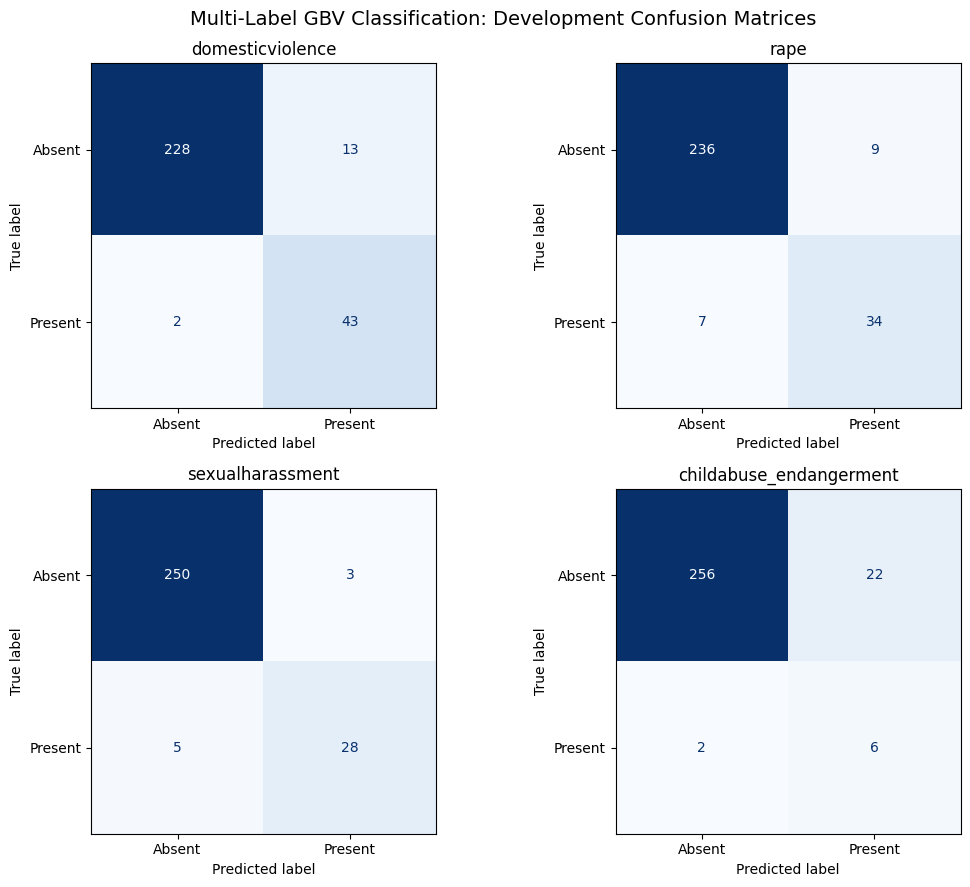

Narratives evaluated: 286


In [31]:
# Generating the confusion matrices
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

best_multilabel_model.eval()

chunk_predictions = []

with torch.no_grad():
    for batch in dev_loader:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)

        outputs = best_multilabel_model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        probabilities = torch.sigmoid(
            outputs.logits
        ).cpu().numpy()

        for narrative_id, probs, labels in zip(
            batch["narrative_id"],
            probabilities,
            batch["gbv_type_labels"].cpu().numpy()
        ):
            chunk_predictions.append({
                "narrative_id": narrative_id,
                "probabilities": probs,
                "true_labels": labels
            })

# Aggregate predictions at narrative level
chunk_predictions_df = pd.DataFrame(chunk_predictions)

multilabel_dev_predictions = (
    chunk_predictions_df.groupby("narrative_id")
    .agg({
        "probabilities": lambda x: np.mean(
            np.stack(x), axis=0
        ),
        "true_labels": "first"
    })
    .reset_index()
)

# Actual labels and predicted probabilities
y_true = np.stack(
    multilabel_dev_predictions["true_labels"]
).astype(int)

y_prob = np.stack(
    multilabel_dev_predictions["probabilities"]
)

# Initial classification threshold
y_pred = (y_prob >= 0.5).astype(int)

# Plot four confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for i, category in enumerate(gbv_categories):

    cm = confusion_matrix(
        y_true[:, i],
        y_pred[:, i],
        labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Absent", "Present"]
    )

    disp.plot(
        ax=axes.flat[i],
        cmap="Blues",
        colorbar=False
    )

    axes.flat[i].set_title(category)

plt.suptitle(
    "Multi-Label GBV Classification: Development Confusion Matrices",
    fontsize=14
)

plt.tight_layout()
plt.show()

print("Narratives evaluated:", len(multilabel_dev_predictions))

The best-performing DistilBERT model (Epoch 3) was evaluated on **286 development narratives** using a classification threshold of `0.5` for each GBV category.

Predictions from multiple chunks were averaged to obtain one prediction per narrative.

| GBV Category | True Positives | True Negatives | False Positives | False Negatives |
|---|---|---|---|---|
| Domestic Violence | 43 | 228 | 13 | 2 |
| Rape | 34 | 236 | 9 | 7 |
| Sexual Harassment | 28 | 250 | 3 | 5 |
| Child Abuse/Endangerment | 6 | 256 | 22 | 2 |

**Observations:**

- **Domestic Violence:** The model correctly identified 43 out of 45 positive cases, demonstrating high recall, although 13 false positives were recorded.
- **Rape:** The model correctly identified 34 out of 41 positive cases, with 7 false negatives.
- **Sexual Harassment:** The model identified 28 out of 33 positive cases but missed 5, indicating room for improvement in recall.
- **Child Abuse/Endangerment:** The model identified 6 positive cases and produced 22 false positives, resulting in very low precision.

The model demonstrated strong recall across the four GBV categories but produced several false positives, particularly for child abuse/endangerment. This may be partly influenced by the high positive class weight assigned to the minority category.

In [38]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

threshold_results = []

for i, category in enumerate(gbv_categories):

    actual = y_true[:, i]
    probabilities = y_prob[:, i]

    for threshold in np.arange(0.10, 1.0, 0.05):

        predicted = (probabilities >= threshold).astype(int)

        threshold_results.append({
            "Category": category,
            "Threshold": round(float(threshold), 2),
            "Precision": precision_score(
                actual, predicted, zero_division=0
            ),
            "Recall": recall_score(
                actual, predicted, zero_division=0
            ),
            "F1 Score": f1_score(
                actual, predicted, zero_division=0
            ),
            "False Positives": int(
                ((actual == 0) & (predicted == 1)).sum()
            ),
            "False Negatives": int(
                ((actual == 1) & (predicted == 0)).sum()
            )
        })

threshold_df = pd.DataFrame(threshold_results)

# Select the highest-F1 threshold for each category
best_thresholds = (
    threshold_df
    .sort_values(
        ["Category", "F1 Score", "Threshold"],
        ascending=[True, False, True]
    )
    .drop_duplicates(subset="Category")
    .sort_values("Category")
)

display(best_thresholds.round(4))

,Category,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives
71,childabuse_endangerment,0.95,0.5556,0.6250,0.5882,4,3
15,domesticviolence,0.85,0.8889,0.8889,0.8889,5,5
21,rape,0.25,0.7647,0.9512,0.8478,12,2
42,sexualharassment,0.40,0.9062,0.8788,0.8923,3,4


Category-specific threshold tuning was performed on the development dataset to improve the precision-recall balance of the DistilBERT multi-label classifier.

The F1-optimal thresholds were:

- **Domestic Violence:** 0.85, achieving an F1-score of 88.89%.
- **Rape:** 0.25, achieving an F1-score of 84.78%.
- **Sexual Harassment:** 0.40, achieving an F1-score of 89.23%.
- **Child Abuse/Endangerment:** 0.95, achieving an F1-score of 58.82%.

The overall macro F1-score increased from **71.73% at the default threshold of 0.50 to approximately 80.43% after threshold tuning**.

However, higher thresholds increased false negatives for some categories. Domestic violence missed five positive cases at its F1-optimal threshold, while child abuse/endangerment missed three of eight positive cases.

In [39]:
from sklearn.metrics import precision_score, recall_score, f1_score
import numpy as np
import pandas as pd

tuned_thresholds = {
    "domesticviolence": 0.85,
    "rape": 0.25,
    "sexualharassment": 0.40,
    "childabuse_endangerment": 0.95
}

comparison_results = []

for i, category in enumerate(gbv_categories):

    actual = y_true[:, i]

    for strategy, threshold in [
        ("Default", 0.50),
        ("F1-Optimized", tuned_thresholds[category])
    ]:

        predicted = (y_prob[:, i] >= threshold).astype(int)

        comparison_results.append({
            "Category": category,
            "Strategy": strategy,
            "Threshold": threshold,
            "Precision": precision_score(actual, predicted, zero_division=0),
            "Recall": recall_score(actual, predicted, zero_division=0),
            "F1": f1_score(actual, predicted, zero_division=0),
            "False Positives": int(((actual == 0) & (predicted == 1)).sum()),
            "False Negatives": int(((actual == 1) & (predicted == 0)).sum())
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Category,Strategy,Threshold,Precision,Recall,F1,False Positives,False Negatives
0,domesticviolence,Default,0.50,0.7679,0.9556,0.8515,13,2
1,domesticviolence,F1-Optimized,0.85,0.8889,0.8889,0.8889,5,5
2,rape,Default,0.50,0.7907,0.8293,0.8095,9,7
3,rape,F1-Optimized,0.25,0.7647,0.9512,0.8478,12,2
4,sexualharassment,Default,0.50,0.9032,0.8485,0.8750,3,5
5,sexualharassment,F1-Optimized,0.40,0.9062,0.8788,0.8923,3,4
6,childabuse_endangerment,Default,0.50,0.2143,0.7500,0.3333,22,2
7,childabuse_endangerment,F1-Optimized,0.95,0.5556,0.6250,0.5882,4,3


In [40]:
# Examining the child-abuse thresholds more closely
child_idx = gbv_categories.index("childabuse_endangerment")

child_results = []

for threshold in np.arange(0.50, 1.0, 0.05):

    actual = y_true[:, child_idx]
    predicted = (y_prob[:, child_idx] >= threshold).astype(int)

    child_results.append({
        "Threshold": round(float(threshold), 2),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0),
        "False Positives": int(((actual == 0) & (predicted == 1)).sum()),
        "False Negatives": int(((actual == 1) & (predicted == 0)).sum())
    })

child_threshold_df = pd.DataFrame(child_results)

display(child_threshold_df.round(4))

,Threshold,Precision,Recall,F1,False Positives,False Negatives
0,0.50,0.2143,0.750,0.3333,22,2
1,0.55,0.2308,0.750,0.3529,20,2
2,0.60,0.2500,0.750,0.3750,18,2
3,0.65,0.2857,0.750,0.4138,15,2
4,0.70,0.3158,0.750,0.4444,13,2
5,0.75,0.3333,0.750,0.4615,12,2
6,0.80,0.3750,0.750,0.5000,10,2
7,0.85,0.4000,0.750,0.5217,9,2
8,0.90,0.4286,0.750,0.5455,8,2
9,0.95,0.5556,0.625,0.5882,4,3


In [41]:
# Saving the selected thresholds
salama_thresholds = {
    "domesticviolence": 0.50,
    "rape": 0.25,
    "sexualharassment": 0.40,
    "childabuse_endangerment": 0.90
}

print("Selected Salama multi-label thresholds:")
for category, threshold in salama_thresholds.items():
    print(f"{category}: {threshold}")

Selected Salama multi-label thresholds:
domesticviolence: 0.5
rape: 0.25
sexualharassment: 0.4
childabuse_endangerment: 0.9


Category-specific thresholds were selected using the development dataset to balance precision, recall, and F1-score, while prioritizing the identification of GBV-related cases.

The selected thresholds were:

- **Domestic Violence:** 0.50
- **Rape:** 0.25
- **Sexual Harassment:** 0.40
- **Child Abuse/Endangerment:** 0.90

For child abuse/endangerment, a threshold of 0.90 was preferred over the F1-optimal threshold of 0.95 because it maintained 75% recall while reducing false positives from 22 to 8.

The selected thresholds achieved a **macro F1-score of approximately 79.34%**, with 36 false positives and 10 false negatives across the four categories.

These thresholds were selected using development data and will be evaluated on the unseen test dataset to assess generalization.

**GBV Event Status temporal classification**

We want to train the model to read tenses of these narratives and read whether a narrative entered is ongoing(0), past(1) or past and ongoing(2). Class imbalance for the past and ongoing category will also be handled carefully and interperated cautiously.

In [42]:
# Checking the temporal label distribution
import pandas as pd

train_temporal_df = pd.DataFrame(train_chunks)
dev_temporal_df = pd.DataFrame(dev_chunks)

print("Training temporal labels:")
print(
    train_temporal_df
    .drop_duplicates("narrative_id")["status_label"]
    .value_counts()
    .sort_index()
)

print("\nDevelopment temporal labels:")
print(
    dev_temporal_df
    .drop_duplicates("narrative_id")["status_label"]
    .value_counts()
    .sort_index()
)

Training temporal labels:
status_label
-100    1762
 0       763
 1       475
 2        19
Name: count, dtype: int64

Development temporal labels:
status_label
-100    166
 0       70
 1       47
 2        3
Name: count, dtype: int64


We'll use class-weighted loss to help the model pay more attention to underrepresented classes. However, with only three development examples of past and ongoing, its evaluation metrics will be unstable.

The -100 label will be ignored during training because those narratives do not have an applicable temporal classification.

In [43]:
# Initializing the temporal DistilBERT model
import torch
import torch.nn as nn
from transformers import AutoModelForSequenceClassification

# Initialize temporal classification model
temporal_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=3
).to(device)

# Count applicable temporal labels from training narratives
temporal_counts = (
    train_temporal_df
    .drop_duplicates("narrative_id")["status_label"]
    .value_counts()
)

# Calculate class weights using applicable labels only
counts = torch.tensor(
    [temporal_counts[i] for i in range(3)],
    dtype=torch.float32
)

class_weights = counts.sum() / (3 * counts)

# Avoid extremely large weights for the rarest class
class_weights = torch.clamp(class_weights, max=10.0).to(device)

# Ignore non-applicable labels (-100)
temporal_loss_fn = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=-100
)

print("Temporal class weights:", class_weights)
print("Temporal model initialized successfully!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Temporal class weights: tensor([ 0.5491,  0.8821, 10.0000], device='cuda:0')
Temporal model initialized successfully!


In [44]:
# Setting up the optimizer and learning-rate scheduler
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# Training configuration
temporal_epochs = 3

temporal_optimizer = AdamW(
    temporal_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

# Total training steps
total_steps = len(train_loader) * temporal_epochs

# Warmup steps (10%)
warmup_steps = int(0.10 * total_steps)

temporal_scheduler = get_linear_schedule_with_warmup(
    temporal_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print("Training batches:", len(train_loader))
print("Total training steps:", total_steps)
print("Warmup steps:", warmup_steps)

Training batches: 407
Total training steps: 1221
Warmup steps: 122


In [45]:
# Creating the temporal training function
from tqdm.auto import tqdm
import torch

def train_temporal_epoch(
    model,
    dataloader,
    optimizer,
    scheduler,
    loss_fn
):
    model.train()

    total_loss = 0
    valid_batches = 0

    progress_bar = tqdm(dataloader, desc="Training")

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["status_label"].to(device).long()

        # Exclude batches with no applicable temporal labels
        if (labels != -100).sum().item() == 0:
            continue

        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Calculate weighted temporal classification loss
        loss = loss_fn(
            outputs.logits,
            labels
        )

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        valid_batches += 1

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = total_loss / valid_batches

    return average_loss

This function:

1. Loads each batch of tokenized narratives.

2. Checks the temporal labels and skips batches containing only -100.

3. Generates predictions using DistilBERT.

4. Calculates weighted cross-entropy loss to address class imbalance.

5. Updates the model weights through backpropagation.

6. Updates the learning-rate scheduler after each optimizer step.

- ignore_index=-100 ensures non-applicable narratives do not contribute directly to the loss, even when they appear alongside applicable narratives.


In [46]:
# Creating the temporal validation function
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def validate_temporal(model, dataloader, loss_fn):

    model.eval()

    total_loss = 0
    valid_batches = 0
    chunk_predictions = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["status_label"].to(device).long()

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # Calculate loss only for applicable temporal labels
            if (labels != -100).any():

                loss = loss_fn(outputs.logits, labels)

                total_loss += loss.item()
                valid_batches += 1

            # Convert logits into class probabilities
            probabilities = torch.softmax(
                outputs.logits, dim=1
            ).cpu().numpy()

            for narrative_id, probs, label in zip(
                batch["narrative_id"],
                probabilities,
                labels.cpu().numpy()
            ):

                chunk_predictions.append({
                    "narrative_id": narrative_id,
                    "probabilities": probs,
                    "true_label": int(label)
                })

    # Aggregate chunk probabilities per narrative
    predictions_df = pd.DataFrame(chunk_predictions)

    narrative_predictions = (
        predictions_df
        .groupby("narrative_id")
        .agg({
            "probabilities": lambda x: np.mean(
                np.stack(x), axis=0
            ),
            "true_label": "first"
        })
        .reset_index()
    )

    # Exclude non-applicable narratives
    narrative_predictions = narrative_predictions[
        narrative_predictions["true_label"] != -100
    ].copy()

    y_true_temporal = narrative_predictions[
        "true_label"
    ].to_numpy()

    y_prob_temporal = np.stack(
        narrative_predictions["probabilities"]
    )

    y_pred_temporal = np.argmax(
        y_prob_temporal, axis=1
    )

    # Calculate evaluation metrics
    accuracy = accuracy_score(
        y_true_temporal, y_pred_temporal
    )

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true_temporal,
            y_pred_temporal,
            labels=[0, 1, 2],
            zero_division=0
        )
    )

    results_df = pd.DataFrame({
        "Category": [
            "Past",
            "Ongoing",
            "Past and Ongoing"
        ],
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Support": support
    })

    macro_f1 = np.mean(f1)

    average_loss = (
        total_loss / valid_batches
        if valid_batches > 0 else float("nan")
    )

    return average_loss, accuracy, macro_f1, results_df

This function evaluates the model on the development dataset and calculate accuracy, precision, recall and F1-score for the three temporal classes.

What is does:
1. Calculates validation loss while ignoring -100 labels.
2. Uses softmax to obtain probabilities for the three mutually exclusive temporal classes.
3. Averages probabilities across chunks belonging to the same narrative.
4. Calculates metrics using only applicable narratives.
5. Computes macro F1-score, giving equal importance to all three temporal classes.

In [47]:
# Training and validating for 3 epochs
import pandas as pd
import numpy as np

temporal_history = []
best_temporal_f1 = -1

for epoch in range(temporal_epochs):

    print(f"\nEpoch {epoch + 1}/{temporal_epochs}")
    print("-" * 40)

    # Train
    train_loss = train_temporal_epoch(
        temporal_model,
        train_loader,
        temporal_optimizer,
        temporal_scheduler,
        temporal_loss_fn
    )

    # Validate
    val_loss, accuracy, macro_f1, results_df = validate_temporal(
        temporal_model,
        dev_loader,
        temporal_loss_fn
    )

    print(f"\nTraining Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {accuracy:.4f}")
    print(f"Validation Macro F1: {macro_f1:.4f}")

    print("\nPerformance by Temporal Category:")
    display(results_df.round(4))

    # Record results
    temporal_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Validation Loss": val_loss,
        "Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    # Save best checkpoint
    if macro_f1 > best_temporal_f1:

        best_temporal_f1 = macro_f1

        temporal_model.save_pretrained(
            "salama_temporal_best"
        )

        print("\nBest temporal model saved!")

# Training summary
temporal_history_df = pd.DataFrame(temporal_history)

print("\nTemporal Classification Training Summary:")
display(temporal_history_df.round(4))


Epoch 1/3
----------------------------------------


Training:   0%|          | 0/407 [00:00<?, ?it/s]


Training Loss: 0.8199
Validation Loss: 0.6988
Validation Accuracy: 0.7750
Validation Macro F1: 0.5203

Performance by Temporal Category:


,Category,Precision,Recall,F1 Score,Support
0,Past,0.8116,0.8000,0.8058,70
1,Ongoing,0.7255,0.7872,0.7551,47
2,Past and Ongoing,0.0000,0.0000,0.0000,3


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...


Training Loss: 0.6032
Validation Loss: 0.9703
Validation Accuracy: 0.7917
Validation Macro F1: 0.5265

Performance by Temporal Category:


,Category,Precision,Recall,F1 Score,Support
0,Past,0.7949,0.8857,0.8378,70
1,Ongoing,0.7857,0.7021,0.7416,47
2,Past and Ongoing,0.0000,0.0000,0.0000,3


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Best temporal model saved!

Temporal Classification Training Summary:


,Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
0,1,0.8199,0.6988,0.7750,0.5203
1,2,0.7010,0.8811,0.7833,0.5231
2,3,0.6032,0.9703,0.7917,0.5265


In [48]:
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import pandas as pd
import torch

# Load the best temporal checkpoint
best_temporal_model = AutoModelForSequenceClassification.from_pretrained(
    "salama_temporal_best"
).to(device)

# Collect narrative-level predictions
best_temporal_model.eval()
temporal_predictions = []

with torch.no_grad():
    for batch in dev_loader:
        outputs = best_temporal_model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device)
        )

        probs = torch.softmax(outputs.logits, dim=1).cpu().numpy()

        for narrative_id, prob, label in zip(
            batch["narrative_id"],
            probs,
            batch["status_label"].cpu().numpy()
        ):
            temporal_predictions.append({
                "narrative_id": narrative_id,
                "probabilities": prob,
                "true_label": int(label)
            })

temporal_pred_df = pd.DataFrame(temporal_predictions)

# Average probabilities across chunks
temporal_narratives = (
    temporal_pred_df.groupby("narrative_id")
    .agg({
        "probabilities": lambda x: np.mean(np.stack(x), axis=0),
        "true_label": "first"
    })
    .reset_index()
)

# Exclude non-applicable narratives
temporal_narratives = temporal_narratives[
    temporal_narratives["true_label"] != -100
].copy()

temporal_narratives["predicted_label"] = (
    temporal_narratives["probabilities"]
    .apply(lambda p: int(np.argmax(p)))
)

labels = ["Past", "Ongoing", "Past and Ongoing"]

cm = confusion_matrix(
    temporal_narratives["true_label"],
    temporal_narratives["predicted_label"],
    labels=[0, 1, 2]
)

cm_df = pd.DataFrame(cm, index=labels, columns=labels)

print("Temporal Confusion Matrix:")
display(cm_df)

print("\nClassification Report:")
print(classification_report(
    temporal_narratives["true_label"],
    temporal_narratives["predicted_label"],
    labels=[0, 1, 2],
    target_names=labels,
    zero_division=0
))

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Temporal Confusion Matrix:


,Past,Ongoing,Past and Ongoing
Past,62,8,0
Ongoing,14,33,0
Past and Ongoing,2,1,0



Classification Report:
                  precision    recall  f1-score   support

            Past       0.79      0.89      0.84        70
         Ongoing       0.79      0.70      0.74        47
Past and Ongoing       0.00      0.00      0.00         3

        accuracy                           0.79       120
       macro avg       0.53      0.53      0.53       120
    weighted avg       0.77      0.79      0.78       120



In [49]:
# Examining the missed combined-category cases
# Inspect development narratives labelled Past and Ongoing
combined_cases = temporal_narratives[
    temporal_narratives["true_label"] == 2
].copy()

combined_cases["Past Probability"] = combined_cases[
    "probabilities"
].apply(lambda p: round(float(p[0]), 4))

combined_cases["Ongoing Probability"] = combined_cases[
    "probabilities"
].apply(lambda p: round(float(p[1]), 4))

combined_cases["Combined Probability"] = combined_cases[
    "probabilities"
].apply(lambda p: round(float(p[2]), 4))

display(
    combined_cases[
        [
            "narrative_id",
            "true_label",
            "predicted_label",
            "Past Probability",
            "Ongoing Probability",
            "Combined Probability"
        ]
    ]
)

,narrative_id,true_label,predicted_label,Past Probability,Ongoing Probability,Combined Probability
51,Question 168,2,1,0.2344,0.7583,0.0073
53,Question 170,2,0,0.9067,0.0868,0.0065
206,Question 382,2,0,0.9919,0.0037,0.0044


Instead of forcing the model to select exactly one temporal category, we allow it to identify two characteristics independently.

**Preparing the model to predict only two temporal labels**


In [50]:
# Convert the original temporal classes into two binary labels
temporal_mapping = {
    0: [1, 0],  # Past
    1: [0, 1],  # Ongoing
    2: [1, 1],  # Past and ongoing
    -100: [-100, -100]  # Not applicable
}

# Add labels to the existing chunks
for chunk in train_chunks:
    chunk["temporal_labels"] = temporal_mapping[
        chunk["status_label"]
    ]

for chunk in dev_chunks:
    chunk["temporal_labels"] = temporal_mapping[
        chunk["status_label"]
    ]

# Check the label distribution at narrative level
train_temporal_labels = {}

for chunk in train_chunks:
    train_temporal_labels[chunk["narrative_id"]] = (
        chunk["temporal_labels"]
    )

import pandas as pd

temporal_label_df = pd.DataFrame(
    train_temporal_labels.values(),
    columns=["Past", "Ongoing"]
)

print("Temporal Label Distribution:")
print(temporal_label_df.value_counts().sort_index())

TypeError: string indices must be integers, not 'str'

In [51]:
print("Type:", type(train_chunks))

if isinstance(train_chunks, dict):
    print("First 5 keys:", list(train_chunks.keys())[:5])
    print("First value:", str(next(iter(train_chunks.values())))[:500])

elif isinstance(train_chunks, list):
    print("First item type:", type(train_chunks[0]))
    print("First item:", str(train_chunks[0])[:500])

Type: <class 'pandas.core.frame.DataFrame'>


In [52]:
temporal_mapping = {
    0: [1, 0],       # Past
    1: [0, 1],       # Ongoing
    2: [1, 1],       # Past and ongoing
    -100: [-100, -100]  # Not applicable
}

# Create two temporal labels
train_chunks["temporal_labels"] = train_chunks["status_label"].apply(
    lambda x: temporal_mapping[int(x)]
)

dev_chunks["temporal_labels"] = dev_chunks["status_label"].apply(
    lambda x: temporal_mapping[int(x)]
)

# Check distribution using unique narratives
temporal_label_df = train_chunks.drop_duplicates(
    subset="narrative_id"
)

print("Temporal Label Distribution:")
print(
    temporal_label_df["temporal_labels"]
    .apply(tuple)
    .value_counts()
)

Temporal Label Distribution:
temporal_labels
(-100, -100)    1762
(1, 0)           763
(0, 1)           475
(1, 1)            19
Name: count, dtype: int64


In [53]:
import inspect

print(inspect.getsource(GBVDataset))

OSError: source code not available

In [54]:
# Check the first item in the existing training dataset
sample = train_dataset[0]

print("Dataset item type:", type(sample))

if isinstance(sample, dict):
    for key, value in sample.items():
        print(
            key,
            "| Type:", type(value),
            "| Shape:", getattr(value, "shape", None)
        )
else:
    print("Sample:", sample)

Dataset item type: <class 'dict'>
input_ids | Type: <class 'torch.Tensor'> | Shape: torch.Size([206])
gbv_related | Type: <class 'torch.Tensor'> | Shape: torch.Size([])
gbv_type_labels | Type: <class 'torch.Tensor'> | Shape: torch.Size([4])
status_label | Type: <class 'torch.Tensor'> | Shape: torch.Size([])
narrative_id | Type: <class 'str'> | Shape: None


In [56]:
print(train_dataset.__dict__.keys())

dict_keys(['data'])


In [57]:
import torch

class TemporalMultiLabelDataset(GBVDataset):

    def __getitem__(self, idx):

        # Get the existing dataset fields
        item = super().__getitem__(idx)

        # Add the two temporal labels
        labels = self.data.iloc[idx]["temporal_labels"]

        item["temporal_labels"] = torch.tensor(
            labels,
            dtype=torch.float32
        )

        return item


# Create separate datasets
temporal_train_dataset = TemporalMultiLabelDataset(train_chunks)
temporal_dev_dataset = TemporalMultiLabelDataset(dev_chunks)

# Verify the new labels
sample = temporal_train_dataset[0]

print("Dataset size:", len(temporal_train_dataset))
print("Temporal labels:", sample["temporal_labels"])
print("Temporal label shape:", sample["temporal_labels"].shape)

Dataset size: 3252
Temporal labels: tensor([0., 1.])
Temporal label shape: torch.Size([2])


In [58]:
# Verifying that no narratives or labels were lost accidentally
print("Training chunks:", len(train_chunks))
print("Unique training narratives:", train_chunks["narrative_id"].nunique())

print("\nDevelopment chunks:", len(dev_chunks))
print("Unique development narratives:", dev_chunks["narrative_id"].nunique())

print("\nMissing temporal labels:")
print("Train:", train_chunks["temporal_labels"].isna().sum())
print("Development:", dev_chunks["temporal_labels"].isna().sum())

print("\nTemporal training dataset:", len(temporal_train_dataset))
print("Temporal development dataset:", len(temporal_dev_dataset))

Training chunks: 3252
Unique training narratives: 3019

Development chunks: 328
Unique development narratives: 286

Missing temporal labels:
Train: 0
Development: 0

Temporal training dataset: 3252
Temporal development dataset: 328


In [59]:
# Creating Dataloaders for temporal multi-label classification
from torch.utils.data import DataLoader
import torch

def temporal_collate_fn(batch):

    # Use our existing collate function
    collated = collate_fn(batch)

    # Add the new temporal labels
    collated["temporal_labels"] = torch.stack([
        item["temporal_labels"] for item in batch
    ])

    return collated


# Training DataLoader
temporal_train_loader = DataLoader(
    temporal_train_dataset,
    batch_size=8,
    shuffle=True,
    collate_fn=temporal_collate_fn
)

# Development DataLoader
temporal_dev_loader = DataLoader(
    temporal_dev_dataset,
    batch_size=8,
    shuffle=False,
    collate_fn=temporal_collate_fn
)

# Verify the first batch
batch = next(iter(temporal_train_loader))

print("Training batches:", len(temporal_train_loader))
print("Development batches:", len(temporal_dev_loader))
print("Input shape:", batch["input_ids"].shape)
print("Temporal label shape:", batch["temporal_labels"].shape)
print("Sample temporal labels:")
print(batch["temporal_labels"][:5])

Training batches: 407
Development batches: 41
Input shape: torch.Size([8, 274])
Temporal label shape: torch.Size([8, 2])
Sample temporal labels:
tensor([[   1.,    0.],
        [-100., -100.],
        [-100., -100.],
        [   0.,    1.],
        [   1.,    0.]])


We'll create a new model with two output neurons:

- Output 0: Past
- Output 1: Ongoing

In [60]:
# Initializing the new DistilBERT multi-label model
import torch
import torch.nn as nn
from transformers import AutoModelForSequenceClassification

# Initialize a separate temporal multi-label model
temporal_multilabel_model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert-base-uncased",
    num_labels=2,
    problem_type="multi_label_classification"
).to(device)

# Count positive and negative labels at narrative level
temporal_counts_df = (
    train_chunks
    .drop_duplicates("narrative_id")
    .copy()
)

# Exclude non-applicable narratives
temporal_counts_df = temporal_counts_df[
    temporal_counts_df["status_label"] != -100
]

temporal_labels_array = torch.tensor(
    temporal_counts_df["temporal_labels"].tolist(),
    dtype=torch.float32
)

positive_counts = temporal_labels_array.sum(dim=0)
negative_counts = len(temporal_labels_array) - positive_counts

# Calculate positive class weights
temporal_pos_weights = (
    negative_counts / positive_counts
).to(device)

# Weighted binary cross-entropy loss
temporal_multilabel_loss_fn = nn.BCEWithLogitsLoss(
    pos_weight=temporal_pos_weights,
    reduction="none"
)

print("Positive counts:", positive_counts)
print("Negative counts:", negative_counts)
print("Positive class weights:", temporal_pos_weights)
print("Temporal multi-label model initialized!")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Positive counts: tensor([782., 494.])
Negative counts: tensor([475., 763.])
Positive class weights: tensor([0.6074, 1.5445], device='cuda:0')
Temporal multi-label model initialized!


In [61]:
# Setting up the optimizer and scheduler
from torch.optim import AdamW
from transformers import get_linear_schedule_with_warmup

# Training configuration
temporal_multilabel_epochs = 3

# Optimizer
temporal_multilabel_optimizer = AdamW(
    temporal_multilabel_model.parameters(),
    lr=2e-5,
    weight_decay=0.01
)

# Learning rate scheduler
total_steps = (
    len(temporal_train_loader) * temporal_multilabel_epochs
)

warmup_steps = int(0.10 * total_steps)

temporal_multilabel_scheduler = get_linear_schedule_with_warmup(
    temporal_multilabel_optimizer,
    num_warmup_steps=warmup_steps,
    num_training_steps=total_steps
)

print("Training batches:", len(temporal_train_loader))
print("Total training steps:", total_steps)
print("Warmup steps:", warmup_steps)

Training batches: 407
Total training steps: 1221
Warmup steps: 122


In [62]:
# Creating the temporal multi-label training function
from tqdm.auto import tqdm
import torch

def train_temporal_multilabel_epoch(
    model,
    dataloader,
    optimizer,
    scheduler,
    loss_fn
):

    model.train()

    total_loss = 0
    valid_batches = 0

    progress_bar = tqdm(
        dataloader,
        desc="Temporal Multi-label Training"
    )

    for batch in progress_bar:

        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["temporal_labels"].to(device)

        # Identify applicable temporal labels
        valid_mask = labels != -100

        # Skip batches containing no applicable labels
        if not valid_mask.any():
            continue

        optimizer.zero_grad()

        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask
        )

        # Replace -100 before calculating BCE loss
        safe_labels = torch.where(
            valid_mask,
            labels,
            torch.zeros_like(labels)
        )

        # Calculate loss for each label
        loss_per_label = loss_fn(
            outputs.logits,
            safe_labels
        )

        # Exclude non-applicable labels from the loss
        loss = (
            loss_per_label * valid_mask.float()
        ).sum() / valid_mask.float().sum()

        # Backpropagation
        loss.backward()

        # Prevent excessively large gradients
        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_loss += loss.item()
        valid_batches += 1

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    average_loss = total_loss / valid_batches

    return average_loss

This function:

1. Retrieves the tokenized narratives and their two temporal labels.
2. Identifies valid labels, excluding -100.
3. Generates two logits using DistilBERT.
4. Calculates weighted binary cross-entropy loss.
5. Masks out non-applicable labels so they don't contribute to training.
6. Updates the model weights and learning-rate scheduler.

Since the model predicts past and ongoing independently, we'll use sigmoid probabilities rather than softmax.

In [63]:
# Creating the validation function
import numpy as np
import pandas as pd
import torch

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support
)

def validate_temporal_multilabel(model, dataloader, loss_fn):

    model.eval()

    total_loss = 0
    valid_batches = 0
    chunk_predictions = []

    with torch.no_grad():

        for batch in dataloader:

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["temporal_labels"].to(device)

            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # Mask non-applicable temporal labels
            valid_mask = labels != -100

            if valid_mask.any():

                safe_labels = torch.where(
                    valid_mask,
                    labels,
                    torch.zeros_like(labels)
                )

                loss_per_label = loss_fn(
                    outputs.logits,
                    safe_labels
                )

                loss = (
                    loss_per_label * valid_mask.float()
                ).sum() / valid_mask.float().sum()

                total_loss += loss.item()
                valid_batches += 1

            # Independent probabilities for Past and Ongoing
            probabilities = torch.sigmoid(
                outputs.logits
            ).cpu().numpy()

            for narrative_id, probs, label in zip(
                batch["narrative_id"],
                probabilities,
                labels.cpu().numpy()
            ):

                chunk_predictions.append({
                    "narrative_id": narrative_id,
                    "probabilities": probs,
                    "true_labels": label
                })

    # Aggregate chunk probabilities by narrative
    predictions_df = pd.DataFrame(chunk_predictions)

    narrative_predictions = (
        predictions_df
        .groupby("narrative_id")
        .agg({
            "probabilities": lambda x: np.mean(
                np.stack(x), axis=0
            ),
            "true_labels": "first"
        })
        .reset_index()
    )

    # Exclude narratives where temporal status is not applicable
    narrative_predictions = narrative_predictions[
        narrative_predictions["true_labels"].apply(
            lambda x: np.all(np.asarray(x) != -100)
        )
    ].copy()

    y_true = np.stack(
        narrative_predictions["true_labels"]
    ).astype(int)

    y_prob = np.stack(
        narrative_predictions["probabilities"]
    )

    # Initial threshold of 0.5 for each label
    y_pred = (y_prob >= 0.5).astype(int)

    # Calculate metrics for each temporal label
    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            average=None,
            zero_division=0
        )
    )

    results_df = pd.DataFrame({
        "Category": ["Past", "Ongoing"],
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "Support": support
    })

    macro_f1 = np.mean(f1)

    # Exact-match accuracy: both labels must be correct
    accuracy = accuracy_score(y_true, y_pred)

    average_loss = (
        total_loss / valid_batches
        if valid_batches > 0 else float("nan")
    )

    return average_loss, accuracy, macro_f1, results_df

In [64]:
# Training and Validating for 3 epochs
import pandas as pd

temporal_multilabel_history = []
best_temporal_multilabel_f1 = -1

for epoch in range(temporal_multilabel_epochs):

    print(f"\nEpoch {epoch + 1}/{temporal_multilabel_epochs}")
    print("-" * 40)

    # Train
    train_loss = train_temporal_multilabel_epoch(
        temporal_multilabel_model,
        temporal_train_loader,
        temporal_multilabel_optimizer,
        temporal_multilabel_scheduler,
        temporal_multilabel_loss_fn
    )

    # Validate
    val_loss, accuracy, macro_f1, results_df = (
        validate_temporal_multilabel(
            temporal_multilabel_model,
            temporal_dev_loader,
            temporal_multilabel_loss_fn
        )
    )

    print(f"\nTraining Loss: {train_loss:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Exact-match Accuracy: {accuracy:.4f}")
    print(f"Validation Macro F1: {macro_f1:.4f}")

    print("\nPerformance by Temporal Label:")
    display(results_df.round(4))

    # Save training results
    temporal_multilabel_history.append({
        "Epoch": epoch + 1,
        "Training Loss": train_loss,
        "Validation Loss": val_loss,
        "Exact-match Accuracy": accuracy,
        "Macro F1": macro_f1
    })

    # Save the best-performing model
    if macro_f1 > best_temporal_multilabel_f1:

        best_temporal_multilabel_f1 = macro_f1

        temporal_multilabel_model.save_pretrained(
            "salama_temporal_multilabel_best"
        )

        print("\nBest temporal multi-label model saved!")

# Display training summary
temporal_multilabel_history_df = pd.DataFrame(
    temporal_multilabel_history
)

print("\nTemporal Multi-label Training Summary:")
display(temporal_multilabel_history_df.round(4))


Epoch 1/3
----------------------------------------


Temporal Multi-label Training:   0%|          | 0/407 [00:00<?, ?it/s]


Training Loss: 0.6268
Validation Loss: 0.6878
Exact-match Accuracy: 0.6583
Validation Macro F1: 0.5493

Performance by Temporal Label:


,Category,Precision,Recall,F1 Score,Support
0,Past,0.6577,1.00,0.7935,73
1,Ongoing,1.0000,0.18,0.3051,50


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Temporal Multi-label Training:   0%|          | 0/407 [00:00<?, ?it/s]


Training Loss: 0.3258
Validation Loss: 0.7542
Exact-match Accuracy: 0.7833
Validation Macro F1: 0.7729

Performance by Temporal Label:


,Category,Precision,Recall,F1 Score,Support
0,Past,0.7907,0.9315,0.8553,73
1,Ongoing,0.8529,0.5800,0.6905,50



Temporal Multi-label Training Summary:


,Epoch,Training Loss,Validation Loss,Exact-match Accuracy,Macro F1
0,1,0.6268,0.6878,0.6583,0.5493
1,2,0.4943,0.5905,0.7917,0.7894
2,3,0.3258,0.7542,0.7833,0.7729


In [65]:
from transformers import AutoModelForSequenceClassification
import numpy as np
import pandas as pd
import torch

# Load best checkpoint (Epoch 2)
best_temporal_multilabel_model = (
    AutoModelForSequenceClassification.from_pretrained(
        "salama_temporal_multilabel_best"
    ).to(device)
)

best_temporal_multilabel_model.eval()

chunk_results = []

with torch.no_grad():
    for batch in temporal_dev_loader:

        outputs = best_temporal_multilabel_model(
            input_ids=batch["input_ids"].to(device),
            attention_mask=batch["attention_mask"].to(device)
        )

        probabilities = torch.sigmoid(
            outputs.logits
        ).cpu().numpy()

        for narrative_id, probs, labels in zip(
            batch["narrative_id"],
            probabilities,
            batch["temporal_labels"].cpu().numpy()
        ):
            chunk_results.append({
                "narrative_id": narrative_id,
                "past_probability": float(probs[0]),
                "ongoing_probability": float(probs[1]),
                "true_labels": tuple(labels.astype(int))
            })

# Aggregate predictions at narrative level
temporal_eval_df = pd.DataFrame(chunk_results)

temporal_eval_df = (
    temporal_eval_df
    .groupby("narrative_id", as_index=False)
    .agg({
        "past_probability": "mean",
        "ongoing_probability": "mean",
        "true_labels": "first"
    })
)

# Keep only applicable narratives
temporal_eval_df = temporal_eval_df[
    temporal_eval_df["true_labels"] != (-100, -100)
].copy()

# Apply initial thresholds
temporal_eval_df["predicted_labels"] = list(zip(
    (temporal_eval_df["past_probability"] >= 0.5).astype(int),
    (temporal_eval_df["ongoing_probability"] >= 0.5).astype(int)
))

# Compare actual and predicted combinations
combination_table = pd.crosstab(
    temporal_eval_df["true_labels"].astype(str),
    temporal_eval_df["predicted_labels"].astype(str),
    rownames=["Actual"],
    colnames=["Predicted"]
)

print("Temporal Combination Confusion Table:")
display(combination_table)

print("\nPast and Ongoing Narratives:")
display(
    temporal_eval_df[
        temporal_eval_df["true_labels"] == (1, 1)
    ][[
        "narrative_id",
        "past_probability",
        "ongoing_probability",
        "predicted_labels"
    ]]
)

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Temporal Combination Confusion Table:


Predicted,"(0, 1)","(1, 0)","(1, 1)"
Actual,,,
"(np.int64(0), np.int64(1))",31,16,0
"(np.int64(1), np.int64(0))",5,64,1
"(np.int64(1), np.int64(1))",0,3,0



Past and Ongoing Narratives:


,narrative_id,past_probability,ongoing_probability,predicted_labels
51,Question 168,0.967584,0.033252,"(1, 0)"
53,Question 170,0.944248,0.057112,"(1, 0)"
206,Question 382,0.971328,0.027778,"(1, 0)"


In [66]:
# Examining mixed ongoing narratives
# Select narratives with an ongoing component
ongoing_cases = temporal_eval_df[
    temporal_eval_df["true_labels"].apply(
        lambda labels: labels[1] == 1
    )
].copy()

# Summarize ongoing prediction probabilities
print("Ongoing Probability Distribution:")
display(
    ongoing_cases["ongoing_probability"].describe()
)

# Examine cases missed at the default 0.5 threshold
missed_ongoing = ongoing_cases[
    ongoing_cases["ongoing_probability"] < 0.5
].copy()

print("\nMissed ongoing narratives:", len(missed_ongoing))

display(
    missed_ongoing[
        [
            "narrative_id",
            "true_labels",
            "past_probability",
            "ongoing_probability",
            "predicted_labels"
        ]
    ].sort_values(
        "ongoing_probability",
        ascending=False
    ).head(15)
)

Ongoing Probability Distribution:


,ongoing_probability
count,50.000000
mean,0.608271
std,0.394131
min,0.027778
25%,0.083627
50%,0.890933
75%,0.946520
max,0.961351



Missed ongoing narratives: 19


,narrative_id,true_labels,past_probability,ongoing_probability,predicted_labels
128,Question 254,"(0, 1)",0.533200,0.470075,"(1, 0)"
42,Question 158,"(0, 1)",0.537440,0.462865,"(1, 0)"
212,Question 388,"(0, 1)",0.658784,0.357936,"(1, 0)"
49,Question 166,"(0, 1)",0.652214,0.348464,"(1, 0)"
181,Question 342,"(0, 1)",0.702871,0.290626,"(1, 0)"
120,Question 244,"(0, 1)",0.920107,0.087189,"(1, 0)"
101,Question 224,"(0, 1)",0.923402,0.082439,"(1, 0)"
28,Question 127,"(0, 1)",0.936673,0.061783,"(1, 0)"
127,Question 252,"(0, 1)",0.940673,0.061749,"(1, 0)"
53,Question 170,"(1, 1)",0.944248,0.057112,"(1, 0)"


In [67]:
# Evaluating ongoing thresholds
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Ground-truth ongoing labels
y_true_ongoing = temporal_eval_df["true_labels"].apply(
    lambda labels: labels[1]
).to_numpy()

threshold_results = []

for threshold in [0.05, 0.10, 0.20, 0.30, 0.40, 0.50]:

    y_pred_ongoing = (
        temporal_eval_df["ongoing_probability"] >= threshold
    ).astype(int).to_numpy()

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_true_ongoing, y_pred_ongoing, zero_division=0
        ),
        "Recall": recall_score(
            y_true_ongoing, y_pred_ongoing, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true_ongoing, y_pred_ongoing, zero_division=0
        ),
        "False Positives": int(
            ((y_true_ongoing == 0) & (y_pred_ongoing == 1)).sum()
        ),
        "False Negatives": int(
            ((y_true_ongoing == 1) & (y_pred_ongoing == 0)).sum()
        )
    })

threshold_results_df = pd.DataFrame(threshold_results)

display(threshold_results_df.round(4))

,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives
0,0.05,0.6562,0.84,0.7368,22,8
1,0.10,0.6923,0.72,0.7059,16,14
2,0.20,0.7200,0.72,0.7200,14,14
3,0.30,0.7292,0.70,0.7143,13,15
4,0.40,0.7500,0.66,0.7021,11,17
5,0.50,0.8378,0.62,0.7126,6,19


In [68]:
# Evaluating temporal combinations using a threhold of 0.05
temporal_thresholds = {
    "past": 0.50,
    "ongoing": 0.05
}

# Generate updated predictions
temporal_eval_df["predicted_labels_tuned"] = list(zip(
    (
        temporal_eval_df["past_probability"]
        >= temporal_thresholds["past"]
    ).astype(int),

    (
        temporal_eval_df["ongoing_probability"]
        >= temporal_thresholds["ongoing"]
    ).astype(int)
))

# Compare actual and predicted temporal combinations
tuned_combination_table = pd.crosstab(
    temporal_eval_df["true_labels"].astype(str),
    temporal_eval_df["predicted_labels_tuned"].astype(str),
    rownames=["Actual"],
    colnames=["Predicted"]
)

print("Temporal Combination Confusion Table (Tuned):")
display(tuned_combination_table)

# Examine the three combined-category narratives
print("\nPast and Ongoing Narratives:")

display(
    temporal_eval_df[
        temporal_eval_df["true_labels"] == (1, 1)
    ][[
        "narrative_id",
        "past_probability",
        "ongoing_probability",
        "predicted_labels_tuned"
    ]]
)

Temporal Combination Confusion Table (Tuned):


Predicted,"(0, 1)","(1, 0)","(1, 1)"
Actual,,,
"(np.int64(0), np.int64(1))",31,6,10
"(np.int64(1), np.int64(0))",5,48,17
"(np.int64(1), np.int64(1))",0,2,1



Past and Ongoing Narratives:


,narrative_id,past_probability,ongoing_probability,predicted_labels_tuned
51,Question 168,0.967584,0.033252,"(1, 0)"
53,Question 170,0.944248,0.057112,"(1, 1)"
206,Question 382,0.971328,0.027778,"(1, 0)"


In [69]:
# Comparing default and tuned temporal predictions
from sklearn.metrics import classification_report, accuracy_score

# Convert label combinations into readable categories
temporal_names = {
    (1, 0): "Past",
    (0, 1): "Ongoing",
    (1, 1): "Past and Ongoing",
    (0, 0): "Neither"
}

y_true = temporal_eval_df["true_labels"].apply(
    lambda x: temporal_names[tuple(x)]
)

y_default = temporal_eval_df["predicted_labels"].apply(
    lambda x: temporal_names[tuple(x)]
)

y_tuned = temporal_eval_df["predicted_labels_tuned"].apply(
    lambda x: temporal_names[tuple(x)]
)

for name, predictions in [
    ("Default Threshold (0.50)", y_default),
    ("Tuned Threshold (0.05 ongoing)", y_tuned)
]:
    print(f"\n{name}")
    print("Accuracy:", round(accuracy_score(y_true, predictions), 4))

    print(classification_report(
        y_true,
        predictions,
        labels=["Past", "Ongoing", "Past and Ongoing"],
        zero_division=0
    ))


Default Threshold (0.50)
Accuracy: 0.7917
                  precision    recall  f1-score   support

            Past       0.77      0.91      0.84        70
         Ongoing       0.86      0.66      0.75        47
Past and Ongoing       0.00      0.00      0.00         3

        accuracy                           0.79       120
       macro avg       0.54      0.52      0.53       120
    weighted avg       0.79      0.79      0.78       120


Tuned Threshold (0.05 ongoing)
Accuracy: 0.6667
                  precision    recall  f1-score   support

            Past       0.86      0.69      0.76        70
         Ongoing       0.86      0.66      0.75        47
Past and Ongoing       0.04      0.33      0.06         3

        accuracy                           0.67       120
       macro avg       0.58      0.56      0.52       120
    weighted avg       0.84      0.67      0.74       120



We shall set the default 0.50 threshold as our current baseline. The tuned threshold sacrifices too much accuracy for a very small improvement in combined-category detection.

In [70]:
# Inspecting combined category training narratives
# Get one row per narrative
temporal_train_narratives = train_chunks.drop_duplicates(
    subset="narrative_id"
).copy()

# Select past-and-ongoing narratives
combined_train = temporal_train_narratives[
    temporal_train_narratives["status_label"] == 2
].copy()

print("Number of combined narratives:", len(combined_train))
print("\nAvailable columns:")
print(combined_train.columns.tolist())

# Display identifiers and text where available
text_column = next(
    (
        col for col in ["question_text", "text", "narrative"]
        if col in combined_train.columns
    ),
    None
)

if text_column:
    display(
        combined_train[
            ["narrative_id", text_column]
        ].head(5)
    )
else:
    print("No narrative text column found.")

Number of combined narratives: 19

Available columns:
['narrative_id', 'input_ids', 'gbv_related', 'gbv_type_labels', 'gbv_event_status', 'status_label', 'temporal_labels']
No narrative text column found.


In [71]:
# Decode tokenized narratives into readable text
combined_train["decoded_text"] = combined_train["input_ids"].apply(
    lambda tokens: tokenizer.decode(
        tokens,
        skip_special_tokens=True
    )
)

# Display the first 5 examples
for _, row in combined_train.head(5).iterrows():

    print(f"\nNarrative ID: {row['narrative_id']}")
    print(f"Text: {row['decoded_text']}")
    print("-" * 70)


Narrative ID: Question 182
Text: workplace sa. need advice. i ’ m a 27f and i ’ m being harassed / assaulted by a 60m. at first it started with him making jokes about him taking me on a date but i always laughed it off because he did the same thing with everyone else my age. fast forward to two years later, he ’ s newly widowed and has become more bold with coming up to me ; touching me kissing me etc. i went to my manager the first time it happened but he told me that it was my fault and that i was in the wrong because by not standing up for myself i was encouraging the behavior. basically told me that he wouldn ’ t do anything about it and that it was my problem to deal with because it would make me grow as a person. this is the same manager who knows about my sexual assault as a child and that my response to unwanted advances is to shut down and let it happen. i mentioned it to some other coworkers and they just laughed it off and said “ yeah he ’ s in love with you good luck. ” fl

In [72]:
import os
import shutil
from transformers import AutoTokenizer

# Create a folder for the models
os.makedirs("salama_models", exist_ok=True)

# Copy the two best trained model checkpoints
shutil.copytree(
    "salama_binary_best",
    "salama_models/binary_model",
    dirs_exist_ok=True
)

shutil.copytree(
    "salama_multilabel_best",
    "salama_models/multilabel_model",
    dirs_exist_ok=True
)

# Save the DistilBERT tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    "distilbert-base-uncased"
)

tokenizer.save_pretrained(
    "salama_models/tokenizer"
)

print("Models and tokenizer saved successfully!")

print("\nSaved folders:")
print(os.listdir("salama_models"))

Models and tokenizer saved successfully!

Saved folders:
['binary_model', 'tokenizer', 'multilabel_model']
